# Diagnóstico dos dados NASA POWER (horários)

Este notebook lê o CSV horário baixado do NASA POWER (pasta `02_dados/nasa_power`) e mostra
**onde faltam dados**, **onde há valores estranhos** e se os dados são **coerentes fisicamente**
(radiação × posição do sol, pressão × altitude, vento a 2 m × 10 m). No fim há gráficos de
visualização e um **resumo consolidado**.

**Nada é corrigido aqui**, o notebook só mostra.

**O que é o NASA POWER:** não é uma estação. Os valores vêm de **reanálise e satélite**: MERRA-2 para
temperatura, umidade, pressão e vento, e CERES SYN1deg para a radiação. Cada valor representa uma
célula de grade de ~0,5° × 0,625° (cerca de 55 km × 65 km) em volta do ponto pedido, e não o ponto
exato da estação SONDA. Isso explica parte das diferenças em relação à SONDA (seção 5).

Roteiro:
1. Configuração e leitura (cabeçalho do arquivo)
2. Registros ausentes e repetidos
3. Valores faltantes por variável (código −999)
4. Valores estranhos: as regras e os episódios encontrados
5. Coerência física: convenção de horário, pressão × altitude, vento 2 m × 10 m
6. Visualização: séries, médias mensais, ciclo diurno, mapas dia × hora, distribuições
7. Resumo consolidado
8. Exportação das tabelas

**Horário:** **UTC**. A coluna `HR` marca o **início** da hora (o valor de `HR = 14` é a média de
14:00 a 14:59 UTC), como a seção 5.1 confere. **Na SONDA é o contrário:** o `TIMESTAMP` marca o
**fim** do intervalo. As tabelas mostram o início em UTC e também em hora local (UTC−3).

## 1. Configuração e leitura

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

RAIZ = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "config").is_dir())
sys.path.insert(0, str(RAIZ))

from config.caminhos_e_parametros import PASTA_NASA_POWER, PASTA_SONDA_MD
from src.dados.nasa_power import carregar_nasa_power, irradiancia_topo

ARQUIVO = sorted(PASTA_NASA_POWER.glob("POWER_Point_Hourly_*.csv"))[-1]  # ou um Path para outro arquivo
PASSO = pd.Timedelta(hours=1)
FUSO_LOCAL = pd.Timedelta(hours=-3)
ALTITUDE_ESTACAO = 574        # m, estacao SONDA-CPA (confirmar no metadado oficial da SONDA)
COMPARAR_PRESSAO_SONDA = True  # le a pressao media da SONDA no mesmo periodo (secao 5.2)
SALVAR_TABELAS = True
PASTA_SAIDA = PASTA_NASA_POWER / "diagnostico"

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Arquivo:", ARQUIVO.name)

Arquivo: POWER_Point_Hourly_20231201_20260630_022d69S_045d01W_UTC.csv


O cabeçalho do arquivo diz onde fica o ponto, a elevação usada pelo modelo, o código de valor
faltante e o que é cada coluna. A leitura (`carregar_nasa_power`, em `src/dados/nasa_power.py`) já troca
o código de falta (−999) por `NaN`.

In [2]:
dados, cabecalho = carregar_nasa_power(ARQUIVO)
parametros = cabecalho["parametros"]
VARIAVEIS = list(parametros["variavel"])
UNIDADES = dict(zip(parametros["variavel"], parametros["unidade"]))
FONTES = dict(zip(parametros["variavel"], parametros["fonte"]))
LATITUDE, LONGITUDE = cabecalho["latitude"], cabecalho["longitude"]
SW, LW = "ALLSKY_SFC_SW_DWN", "ALLSKY_SFC_LW_DWN"

print(f"Ponto pedido: latitude {LATITUDE}, longitude {LONGITUDE}")
print(f"Elevacao media da celula do MERRA-2: {cabecalho['elevacao_modelo_m']:.0f} m "
      f"(estacao SONDA: ~{ALTITUDE_ESTACAO} m)")
print(f"Codigo de falta no arquivo: {cabecalho['codigo_faltante']:g} (vira NaN na leitura)")
print(f"Periodo: {dados.index.min():%d/%m/%Y %H:%M} a {dados.index.max():%d/%m/%Y %H:%M} UTC (inicio da hora)")
display(parametros[["variavel", "fonte", "descricao", "unidade", "descricao_original"]])

Ponto pedido: latitude -22.6896, longitude -45.0062
Elevacao media da celula do MERRA-2: 1028 m (estacao SONDA: ~574 m)
Codigo de falta no arquivo: -999 (vira NaN na leitura)
Periodo: 01/12/2023 00:00 a 30/06/2026 23:00 UTC (inicio da hora)


,variavel,fonte,descricao,unidade,descricao_original
0,T2M,MERRA-2,Temperatura do ar a 2 m,C,MERRA-2 Temperature at 2 Meters (C)
1,ALLSKY_SFC_SW_DWN,CERES,Radiacao de onda curta incidente (ceu real),Wh/m^2,CERES SYN1deg All Sky Surface Shortwave Downwa...
2,ALLSKY_SFC_LW_DWN,CERES,Radiacao de onda longa incidente (ceu real),Wh/m^2,CERES SYN1deg All Sky Surface Longwave Downwar...
3,PS,MERRA-2,Pressao na superficie,kPa,MERRA-2 Surface Pressure (kPa)
4,RH2M,MERRA-2,Umidade relativa a 2 m,%,MERRA-2 Relative Humidity at 2 Meters (%)
5,WS2M,MERRA-2,Velocidade do vento a 2 m,m/s,MERRA-2 Wind Speed at 2 Meters (m/s)
6,WS10M,MERRA-2,Velocidade do vento a 10 m,m/s,MERRA-2 Wind Speed at 10 Meters (m/s)


**Unidades.** A radiação vem em Wh/m² **por hora**: é a energia recebida na hora, que numericamente é
igual à média da irradiância em W/m² naquela hora. Por isso, daqui em diante, ela é tratada como W/m²
(mesma unidade da SONDA). A pressão vem em kPa (1 kPa = 10 hPa = 10 mb).

Funções auxiliares: `intervalos` agrupa horas consecutivas marcadas (faltando ou estranhas) em
episódios, com início, fim e duração.

In [3]:
def formatar_duracao(duracao):
    horas = int(duracao.total_seconds() // 3600)
    dias, horas = divmod(horas, 24)
    partes = [f"{dias} d" if dias else "", f"{horas} h" if horas else ""]
    return " ".join(p for p in partes if p)


def intervalos(mascara):
    mascara = mascara.fillna(False).astype(bool)
    colunas = ["inicio_utc", "fim_utc", "registros", "duracao", "inicio_hora_local"]
    if not mascara.any():
        return pd.DataFrame(columns=colunas)
    grupo = (mascara != mascara.shift()).cumsum()[mascara]
    horarios = pd.Series(mascara.index[mascara], index=mascara.index[mascara])
    tabela = horarios.groupby(grupo.values).agg(["min", "max", "size"]).reset_index(drop=True)
    tabela.columns = ["inicio_utc", "fim_utc", "registros"]
    tabela["duracao"] = (tabela["registros"] * PASSO).map(formatar_duracao)
    tabela["inicio_hora_local"] = (tabela["inicio_utc"] + FUSO_LOCAL).dt.strftime("%d/%m/%Y %H:%M")
    return tabela[colunas]

## 2. Registros ausentes e repetidos

Monta a grade regular de 1 h entre a primeira e a última hora do arquivo. Horas que não existem no
arquivo viram linhas vazias (**registro ausente**); horas que aparecem duas vezes (**repetidas**)
ficam só uma vez.

In [4]:
repetidos = dados.index.duplicated()
dados = dados[~repetidos].sort_index()
grade = pd.date_range(dados.index.min(), dados.index.max(), freq=PASSO, name="tempo")
registro_ausente = pd.Series(~grade.isin(dados.index), index=grade)
dados = dados.reindex(grade)

print(f"Registros esperados (a cada 1 h): {len(grade):,}".replace(",", "."))
print(f"Registros presentes: {(~registro_ausente).sum():,}".replace(",", "."))
print(f"Registros ausentes: {registro_ausente.sum()}")
print(f"Horas repetidas: {repetidos.sum()}")
tabela_ausentes = intervalos(registro_ausente)
display(tabela_ausentes)

Registros esperados (a cada 1 h): 22.632
Registros presentes: 22.632
Registros ausentes: 0
Horas repetidas: 0


,inicio_utc,fim_utc,registros,duracao,inicio_hora_local


## 3. Valores faltantes por variável

Um valor falta quando o registro não existe (seção 2) ou quando o arquivo traz o código −999 ("dado
da fonte faltando ou fora do período disponível"). Isso costuma acontecer no **fim** do período: a
radiação do CERES chega com alguns meses de atraso.

In [5]:
medidas = dados[VARIAVEIS]
faltante = medidas.isna()

linhas_resumo, tabelas_falhas = [], []
for variavel in VARIAVEIS:
    tabela = intervalos(faltante[variavel])
    tabela.insert(0, "variavel", variavel)
    tabela["tipo"] = [
        "registro ausente" if registro_ausente.loc[ini:fim].all() else "codigo -999"
        for ini, fim in zip(tabela["inicio_utc"], tabela["fim_utc"])
    ]
    tabelas_falhas.append(tabela)
    maior = tabela.loc[tabela["registros"].idxmax()] if len(tabela) else None
    linhas_resumo.append({
        "variavel": variavel,
        "unidade": UNIDADES[variavel],
        "faltando": int(faltante[variavel].sum()),
        "faltando_%": round(100 * faltante[variavel].mean(), 3),
        "falhas": len(tabela),
        "maior_falha": maior["duracao"] if maior is not None else "",
        "maior_falha_inicio_utc": maior["inicio_utc"] if maior is not None else pd.NaT,
    })

resumo_faltantes = pd.DataFrame(linhas_resumo)
falhas = pd.concat(tabelas_falhas, ignore_index=True)
display(resumo_faltantes)
if len(falhas):
    display(falhas.sort_values("registros", ascending=False).reset_index(drop=True))
else:
    print("Nenhum valor faltante em nenhuma variavel.")

,variavel,unidade,faltando,faltando_%,falhas,maior_falha,maior_falha_inicio_utc
0,T2M,C,0,0.0,0,,NaT
1,ALLSKY_SFC_SW_DWN,Wh/m^2,0,0.0,0,,NaT
2,ALLSKY_SFC_LW_DWN,Wh/m^2,0,0.0,0,,NaT
3,PS,kPa,0,0.0,0,,NaT
4,RH2M,%,0,0.0,0,,NaT
5,WS2M,m/s,0,0.0,0,,NaT
6,WS10M,m/s,0,0.0,0,,NaT


Nenhum valor faltante em nenhuma variavel.


## 4. Valores estranhos

Cada valor é testado pelas regras abaixo, na ordem, e vale a primeira que ele violar. As regras só
**marcam** os valores, não alteram nada. Os limites ficam na célula seguinte e podem ser ajustados.

| Regra | O que marca | Por quê |
|---|---|---|
| `impossivel` | umidade fora de 0–100 %, radiação ou vento negativos | valores que não existem fisicamente |
| `fora_da_faixa` | valores fora de uma faixa plausível para Cachoeira Paulista (temperatura, pressão, onda longa, vento) | possíveis, mas improváveis aqui: vale olhar |
| `sol_a_noite` | onda curta acima de 1 W/m² com o sol abaixo do horizonte | não há sol à noite; aponta erro de horário |
| `acima_do_topo` | onda curta maior que a irradiância no **topo da atmosfera** | a superfície não recebe mais do que chega ao topo |
| `umidade_100` | umidade exatamente 100 % | ar saturado (nevoeiro, chuva), pode ser real; a regra só mostra onde acontece |
| `vento_2m_maior_10m` | vento a 2 m maior que a 10 m na mesma hora | o vento costuma aumentar com a altura; é estranho, mas pode ocorrer com vento muito fraco |
| `constante` | o mesmo valor repetido por 6 h seguidas ou mais | modelo ou sensor "travado" (não se aplica à radiação à noite nem à umidade em 100 %, que têm regras próprias) |
| `salto_brusco` | variação entre duas horas seguidas maior que o limite, **e** valor longe da mediana das 6 h ao redor | mudança rápida demais para 1 h |

A irradiância no topo da atmosfera é calculada em `irradiancia_topo` (`src/dados/nasa_power.py`), pela
posição do sol em cada hora (fórmulas de Spencer, 1971). É um **resultado matemático**, não um dado.

In [6]:
FAIXA_POSSIVEL = {"RH2M": (0, 100), SW: (0, None), LW: (0, None), "WS2M": (0, None), "WS10M": (0, None)}
FAIXA_PLAUSIVEL = {                      # para Cachoeira Paulista
    "T2M": (-5, 42),                     # C
    "PS": (85, 95),                      # kPa (celula do modelo a ~1000 m: ~90 kPa)
    LW: (150, 550),                      # W/m2
    "WS2M": (0, 20), "WS10M": (0, 30),   # m/s
}
LIMITE_SOL = 1.0                         # W/m2
CONSTANTE_VERIFICAR = ["T2M", LW, "PS", "WS2M", "WS10M"]
HORAS_CONSTANTE = 6
JANELA_MEDIANA = "6h"
LIMITE_SALTO = {"T2M": 8.0, "RH2M": 40.0, "PS": 0.5, LW: 100.0, "WS10M": 4.0}  # por hora

toa = irradiancia_topo(medidas.index, LATITUDE, LONGITUDE, passo=PASSO)

Antes de aplicar o `salto_brusco`, veja como as variações reais se distribuem. Cada histograma mostra
a variação entre horas seguidas (eixo y em escala log), e a linha vermelha é o limite escolhido. A
reanálise é um campo **suave** (sai de um modelo), então saltos isolados são raros. O que se espera
é um ciclo diurno regular, não ruído.

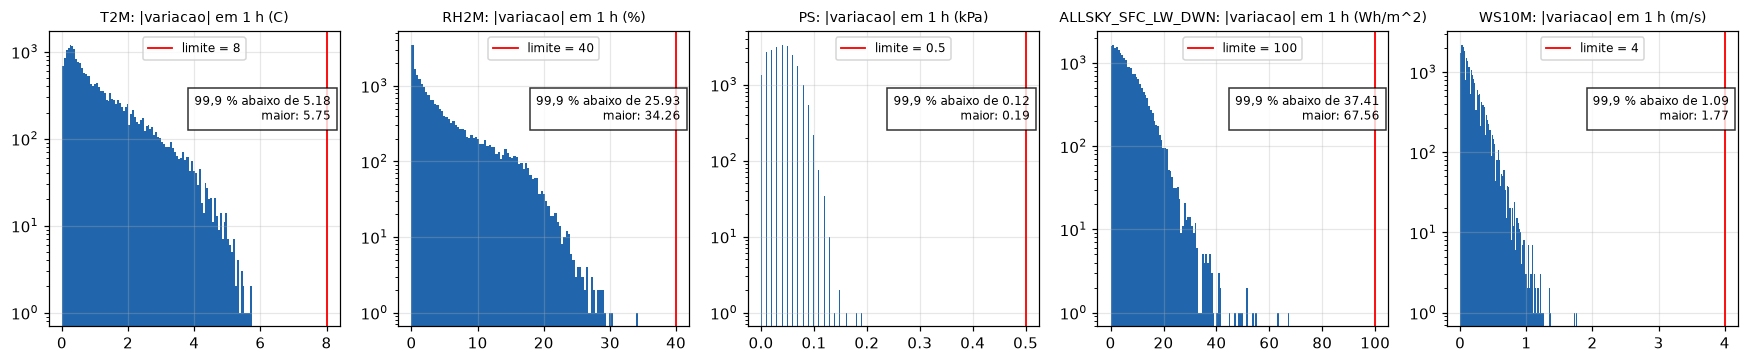

In [7]:
fig, eixos = plt.subplots(1, len(LIMITE_SALTO), figsize=(16, 3.4))
for eixo, (variavel, limite) in zip(eixos, LIMITE_SALTO.items()):
    variacao = medidas[variavel].diff().abs().dropna()
    eixo.hist(variacao, bins=100, color="#2166ac", log=True)
    eixo.axvline(limite, color="red", lw=1.2, label=f"limite = {limite:g}")
    eixo.set_title(f"{variavel}: |variacao| em 1 h ({UNIDADES[variavel]})", fontsize=9)
    eixo.legend(fontsize=8)
    eixo.text(0.97, 0.7, f"99,9 % abaixo de {variacao.quantile(0.999):.2f}\nmaior: {variacao.max():.2f}",
              transform=eixo.transAxes, ha="right", fontsize=8, bbox={"facecolor": "white", "alpha": 0.8})
fig.tight_layout()
plt.show()

In [8]:
def mascara_vazia():
    return pd.DataFrame(False, index=medidas.index, columns=VARIAVEIS)


def fora_de(faixas):
    mascara = mascara_vazia()
    for variavel, (minimo, maximo) in faixas.items():
        if minimo is not None:
            mascara[variavel] |= medidas[variavel] < minimo
        if maximo is not None:
            mascara[variavel] |= medidas[variavel] > maximo
    return mascara


regras = {}
regras["impossivel"] = fora_de(FAIXA_POSSIVEL)
regras["fora_da_faixa"] = fora_de(FAIXA_PLAUSIVEL)

sol_a_noite = mascara_vazia()
sol_a_noite[SW] = (toa == 0) & (medidas[SW] > LIMITE_SOL)
regras["sol_a_noite"] = sol_a_noite

acima_do_topo = mascara_vazia()
acima_do_topo[SW] = medidas[SW] > toa + LIMITE_SOL
regras["acima_do_topo"] = acima_do_topo

umidade_100 = mascara_vazia()
umidade_100["RH2M"] = medidas["RH2M"] == 100
regras["umidade_100"] = umidade_100

vento_2m_maior = mascara_vazia()
vento_2m_maior["WS2M"] = medidas["WS2M"] > medidas["WS10M"]
regras["vento_2m_maior_10m"] = vento_2m_maior

constante = mascara_vazia()
for variavel in CONSTANTE_VERIFICAR:
    serie = medidas[variavel]
    grupo = (serie != serie.shift()).cumsum()
    tamanho = serie.groupby(grupo).transform("size")
    constante[variavel] = (tamanho >= HORAS_CONSTANTE) & serie.notna()
regras["constante"] = constante

salto = mascara_vazia()
for variavel, limite in LIMITE_SALTO.items():
    serie = medidas[variavel]
    mediana = serie.rolling(JANELA_MEDIANA, center=True, min_periods=4).median()
    salto[variavel] = (serie.diff().abs() > limite) & ((serie - mediana).abs() > limite)
regras["salto_brusco"] = salto

# Cada valor recebe a primeira regra que violar
regra_do_valor = pd.DataFrame("", index=medidas.index, columns=VARIAVEIS)
for nome, mascara in regras.items():
    regra_do_valor = regra_do_valor.mask((regra_do_valor == "") & mascara.fillna(False), nome)
estranho = regra_do_valor != ""

contagem = pd.DataFrame({nome: (regra_do_valor == nome).sum() for nome in regras})
contagem["total"] = contagem.sum(axis=1)
display(contagem)

,impossivel,fora_da_faixa,sol_a_noite,acima_do_topo,umidade_100,vento_2m_maior_10m,constante,salto_brusco,total
T2M,0,0,0,0,0,0,0,0,0
ALLSKY_SFC_SW_DWN,0,0,0,0,0,0,0,0,0
ALLSKY_SFC_LW_DWN,0,0,0,0,0,0,0,0,0
PS,0,0,0,0,0,0,0,0,0
RH2M,0,0,0,0,1001,0,0,0,1001
WS2M,0,0,0,0,0,60,18,0,78
WS10M,0,0,0,0,0,0,0,0,0


Episódios de valores estranhos: horas seguidas com a mesma regra viram um episódio, com início, fim,
duração e os valores mínimo e máximo encontrados.

In [9]:
tabelas_estranhos = []
for variavel in VARIAVEIS:
    for nome in regras:
        mascara = regra_do_valor[variavel] == nome
        if not mascara.any():
            continue
        tabela = intervalos(mascara)
        valores = [medidas.loc[ini:fim, variavel] for ini, fim in zip(tabela["inicio_utc"], tabela["fim_utc"])]
        tabela.insert(0, "regra", nome)
        tabela.insert(0, "variavel", variavel)
        tabela["valor_min"] = [v.min() for v in valores]
        tabela["valor_max"] = [v.max() for v in valores]
        tabelas_estranhos.append(tabela)

episodios_estranhos = pd.concat(tabelas_estranhos, ignore_index=True) if tabelas_estranhos else pd.DataFrame()
print(f"{len(episodios_estranhos)} episodios de valores estranhos")
if len(episodios_estranhos):
    resumo_episodios = (episodios_estranhos.groupby(["variavel", "regra"])
                        .agg(episodios=("registros", "size"), horas=("registros", "sum"),
                             maior_episodio_h=("registros", "max"),
                             valor_min=("valor_min", "min"), valor_max=("valor_max", "max")))
    display(resumo_episodios)

284 episodios de valores estranhos


episodios  horas  maior_episodio_h  valor_min  valor_max
variavel regra                                                                       
RH2M     umidade_100               231   1001                11     100.00     100.00
WS2M     constante                   3     18                 6       0.16       0.50
         vento_2m_maior_10m         50     60                 3       0.05       0.51

Para ver a lista completa de uma regra, troque `VER_REGRA` (ou use `None` para todas).

In [10]:
VER_REGRA = "vento_2m_maior_10m"  # ex.: "umidade_100", "constante" ou None

if len(episodios_estranhos):
    tabela = episodios_estranhos if VER_REGRA is None else episodios_estranhos.query("regra == @VER_REGRA")
    display(tabela.sort_values("registros", ascending=False).reset_index(drop=True).head(30))

,variavel,regra,inicio_utc,fim_utc,registros,duracao,inicio_hora_local,valor_min,valor_max
0,WS2M,vento_2m_maior_10m,2025-07-16 13:00:00,2025-07-16 15:00:00,3,3 h,16/07/2025 10:00,0.14,0.21
1,WS2M,vento_2m_maior_10m,2023-12-15 16:00:00,2023-12-15 17:00:00,2,2 h,15/12/2023 13:00,0.21,0.31
2,WS2M,vento_2m_maior_10m,2024-10-23 15:00:00,2024-10-23 16:00:00,2,2 h,23/10/2024 12:00,0.22,0.34
3,WS2M,vento_2m_maior_10m,2024-04-26 16:00:00,2024-04-26 17:00:00,2,2 h,26/04/2024 13:00,0.26,0.30
4,WS2M,vento_2m_maior_10m,2024-09-06 16:00:00,2024-09-06 17:00:00,2,2 h,06/09/2024 13:00,0.35,0.40
5,WS2M,vento_2m_maior_10m,2024-07-21 16:00:00,2024-07-21 17:00:00,2,2 h,21/07/2024 13:00,0.24,0.30
6,WS2M,vento_2m_maior_10m,2025-07-07 17:00:00,2025-07-07 18:00:00,2,2 h,07/07/2025 14:00,0.22,0.25
7,WS2M,vento_2m_maior_10m,2025-08-24 17:00:00,2025-08-24 18:00:00,2,2 h,24/08/2025 14:00,0.42,0.51
8,WS2M,vento_2m_maior_10m,2024-06-05 17:00:00,2024-06-05 18:00:00,2,2 h,05/06/2024 14:00,0.18,0.25
9,WS2M,vento_2m_maior_10m,2023-12-05 16:00:00,2023-12-05 16:00:00,1,1 h,05/12/2023 13:00,0.28,0.28


### Mapa de faltantes e estranhos

Cada coluna é um dia e cada linha, uma variável: quantas horas do dia têm valor faltando (em cima) ou
estranho (embaixo). Branco significa nenhum problema.

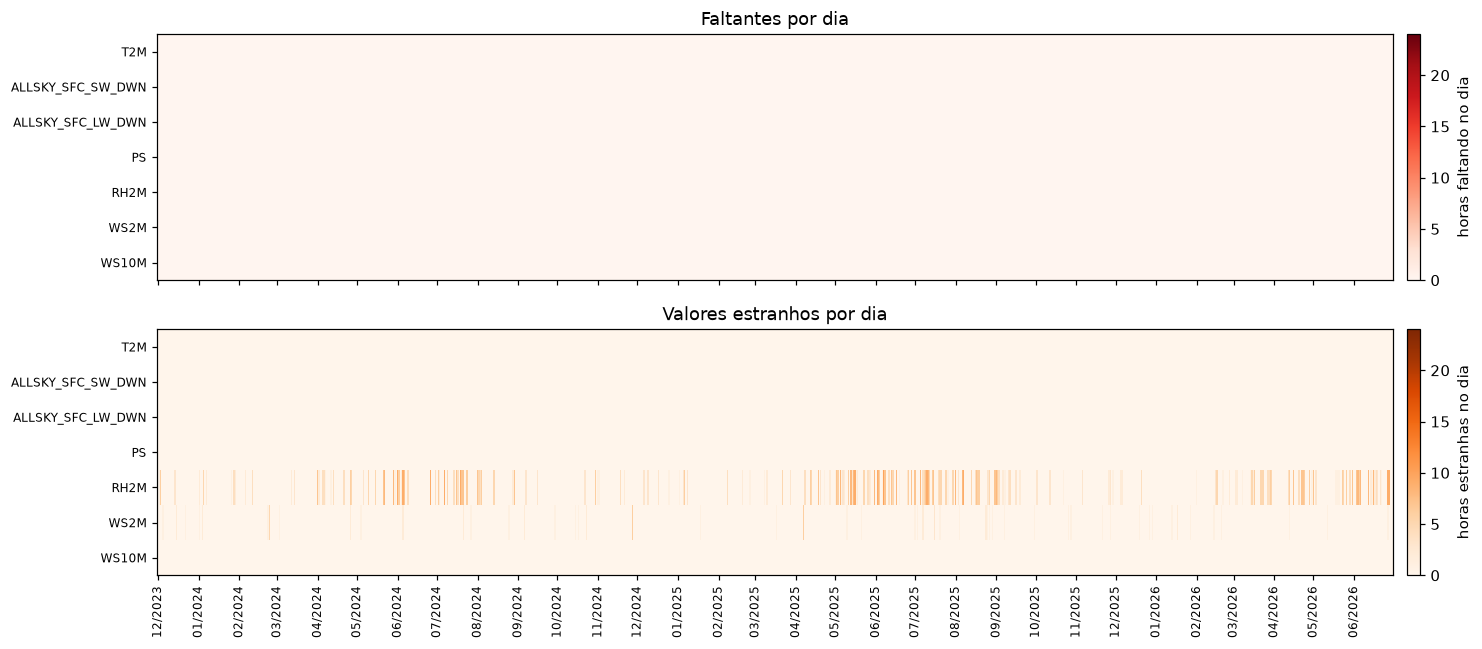

In [11]:
falta_dia = faltante.groupby(faltante.index.normalize()).sum()
estranho_dia = estranho.groupby(estranho.index.normalize()).sum()

fig, (eixo_a, eixo_b) = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
for eixo, tabela, cmap, rotulo in [
    (eixo_a, falta_dia, "Reds", "horas faltando no dia"),
    (eixo_b, estranho_dia, "Oranges", "horas estranhas no dia"),
]:
    imagem = eixo.imshow(tabela.T.to_numpy(), aspect="auto", interpolation="nearest", cmap=cmap, vmin=0, vmax=24)
    eixo.set_yticks(range(len(VARIAVEIS)), VARIAVEIS, fontsize=8)
    eixo.grid(False)
    fig.colorbar(imagem, ax=eixo, label=rotulo, pad=0.01)
dias = falta_dia.index
meses = [i for i, dia in enumerate(dias) if dia.day == 1]
eixo_b.set_xticks(meses, [dias[i].strftime("%m/%Y") for i in meses], rotation=90, fontsize=8)
eixo_a.set_title("Faltantes por dia")
eixo_b.set_title("Valores estranhos por dia")
fig.tight_layout()
plt.show()

## 5. Coerência física

### 5.1 Convenção de horário: `HR` é o início ou o fim da hora?

O arquivo não diz se `HR = 14` é a média de 14:00–14:59 (início) ou de 13:00–13:59 (fim). Para
descobrir, compara-se a onda curta com a irradiância no topo da atmosfera calculada **nas duas
hipóteses**. A hipótese certa é a que não tem sol à noite nem valores acima do topo.

Isto é **evidência computacional**: a conta é exata, e a conclusão vem de ela bater (ou não) com os dados.

,convencao,horas_com_sol_a_noite,horas_acima_do_topo,correlacao_com_topo
0,HR = inicio da hora,0,0,0.9262
1,HR = fim da hora,707,1438,0.8718


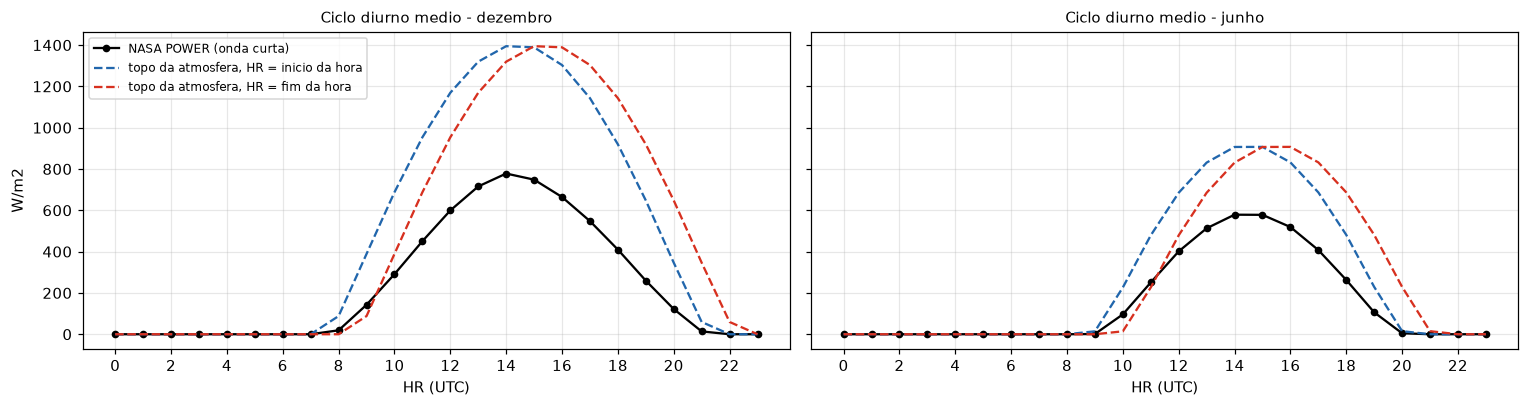

In [12]:
linhas = []
topos = {}
for nome, deslocamento in [("HR = inicio da hora", 0), ("HR = fim da hora", -1)]:
    teto = irradiancia_topo(medidas.index + deslocamento * PASSO, LATITUDE, LONGITUDE, passo=PASSO)
    teto.index = medidas.index
    topos[nome] = teto
    linhas.append({
        "convencao": nome,
        "horas_com_sol_a_noite": int(((teto == 0) & (medidas[SW] > LIMITE_SOL)).sum()),
        "horas_acima_do_topo": int(((teto > 0) & (medidas[SW] > teto + LIMITE_SOL)).sum()),
        "correlacao_com_topo": round(medidas[SW].corr(teto), 4),
    })
teste_horario = pd.DataFrame(linhas)
display(teste_horario)

fig, eixos = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for eixo, (mes, nome_mes) in zip(eixos, [(12, "dezembro"), (6, "junho")]):
    no_mes = medidas.index.month == mes
    hora = medidas.index.hour[no_mes]
    eixo.plot(range(24), medidas.loc[no_mes, SW].groupby(hora).mean(), "o-", color="k", ms=4,
              label="NASA POWER (onda curta)")
    for (nome, teto), cor in zip(topos.items(), ["#2166ac", "#d7301f"]):
        eixo.plot(range(24), teto[no_mes].groupby(hora).mean(), "--", color=cor, label=f"topo da atmosfera, {nome}")
    eixo.set_xticks(range(0, 24, 2))
    eixo.set_xlabel("HR (UTC)")
    eixo.set_title(f"Ciclo diurno medio - {nome_mes}", fontsize=10)
eixos[0].set_ylabel("W/m2")
eixos[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

### 5.2 Pressão × altitude

A pressão do NASA POWER (~90 kPa = ~900 hPa) é bem menor que a da SONDA (~950 hPa). Isso é esperado:
o modelo usa a **elevação média da célula** (cabeçalho: ~1028 m, por incluir a serra), e não a da
estação. Para conferir, a pressão do modelo é "descida" até a altitude da estação pela equação
hipsométrica:

$$p_{estação} = p_{modelo}\,\exp\!\left(\frac{g\,\Delta z}{R_d\,T}\right)$$

com $\Delta z$ = elevação do modelo − altitude da estação, $g$ = 9,81 m/s², $R_d$ = 287 J/(kg·K) e $T$ a
temperatura do ar em K. Usar a temperatura a 2 m no lugar da temperatura média da camada é uma
aproximação, que muda o resultado em menos de 1 hPa.

In [13]:
G, RD = 9.80665, 287.05
delta_z = cabecalho["elevacao_modelo_m"] - ALTITUDE_ESTACAO
pressao_modelo_hpa = medidas["PS"] * 10
pressao_na_estacao = pressao_modelo_hpa * np.exp(G * delta_z / (RD * (medidas["T2M"] + 273.15)))

print(f"Diferenca de altitude (modelo - estacao): {delta_z:.0f} m")
print(f"Pressao media do NASA POWER (na elevacao do modelo): {pressao_modelo_hpa.mean():.1f} hPa")
print(f"Pressao media do NASA POWER levada a {ALTITUDE_ESTACAO} m: {pressao_na_estacao.mean():.1f} hPa")

if COMPARAR_PRESSAO_SONDA:
    sonda = pd.concat(
        [pd.read_csv(a, usecols=["TIMESTAMP", "press"], parse_dates=["TIMESTAMP"])
         for a in sorted(PASTA_SONDA_MD.glob("sonda_MD_*.csv"))],
        ignore_index=True,
    )
    no_periodo = sonda["TIMESTAMP"].between(grade[0], grade[-1] + PASSO)
    pressao_sonda = sonda.loc[no_periodo, "press"].mean()
    print(f"Pressao media da SONDA no mesmo periodo: {pressao_sonda:.1f} hPa "
          f"(diferenca: {pressao_na_estacao.mean() - pressao_sonda:+.1f} hPa)")

Diferenca de altitude (modelo - estacao): 454 m
Pressao media do NASA POWER (na elevacao do modelo): 901.4 hPa
Pressao media do NASA POWER levada a 574 m: 950.4 hPa
Pressao media da SONDA no mesmo periodo: 951.4 hPa (diferenca: -1.0 hPa)


### 5.3 Vento a 2 m × 10 m

Perto do chão, o vento cresce com a altura de forma aproximadamente logarítmica (perfil
logarítmico, válido com atmosfera neutra):

$$\frac{u_{10}}{u_{2}} = \frac{\ln(10/z_0)}{\ln(2/z_0)}$$

em que $z_0$ é a **rugosidade** da superfície: ~0,01 m em gramado, ~0,1 m em plantação, ~1 m em
floresta ou cidade. Pela razão mediana entre os ventos dá para estimar o $z_0$ que o modelo está usando.

Razao mediana WS10M / WS2M: 4.48
Rugosidade equivalente z0: 1.26 m
Horas com WS2M > WS10M: 60


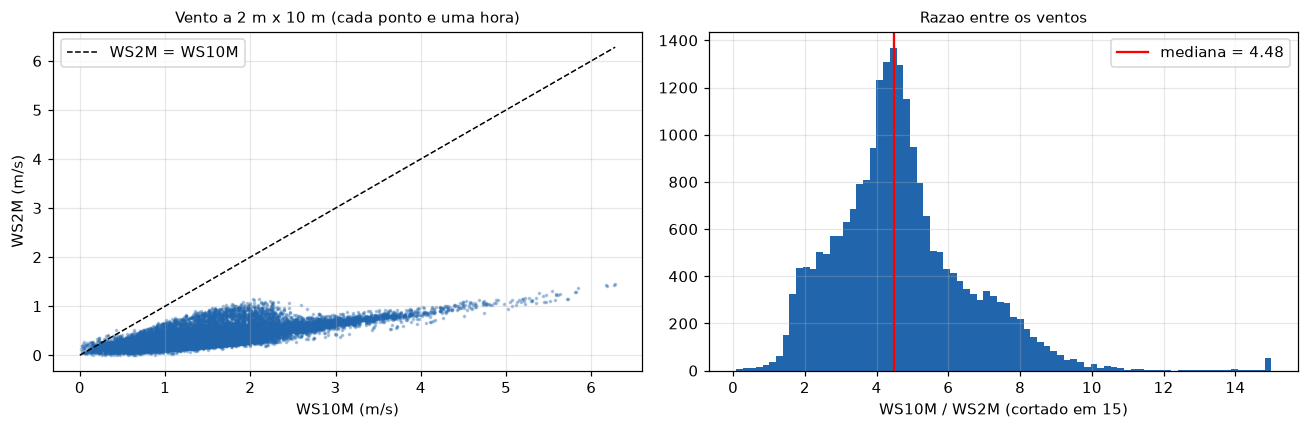

In [14]:
razao_vento = medidas["WS10M"] / medidas["WS2M"].where(medidas["WS2M"] > 0)
razao_mediana = razao_vento.median()
z0 = np.exp((np.log(10) - razao_mediana * np.log(2)) / (1 - razao_mediana))
print(f"Razao mediana WS10M / WS2M: {razao_mediana:.2f}")
print(f"Rugosidade equivalente z0: {z0:.2f} m")
print(f"Horas com WS2M > WS10M: {(medidas['WS2M'] > medidas['WS10M']).sum()}")

fig, (eixo_a, eixo_b) = plt.subplots(1, 2, figsize=(12, 4))
eixo_a.scatter(medidas["WS10M"], medidas["WS2M"], s=2, alpha=0.3, color="#2166ac")
limite = medidas[["WS2M", "WS10M"]].max().max()
eixo_a.plot([0, limite], [0, limite], "k--", lw=1, label="WS2M = WS10M")
eixo_a.set_xlabel("WS10M (m/s)")
eixo_a.set_ylabel("WS2M (m/s)")
eixo_a.legend()
eixo_a.set_title("Vento a 2 m x 10 m (cada ponto e uma hora)", fontsize=10)
eixo_b.hist(razao_vento.clip(upper=15).dropna(), bins=80, color="#2166ac")
eixo_b.axvline(razao_mediana, color="red", label=f"mediana = {razao_mediana:.2f}")
eixo_b.set_xlabel("WS10M / WS2M (cortado em 15)")
eixo_b.legend()
eixo_b.set_title("Razao entre os ventos", fontsize=10)
fig.tight_layout()
plt.show()

## 6. Visualização

### 6.1 Séries completas

Cinza: valores horários. Azul: média diária. Pontos laranja: valores estranhos que **não** são
`umidade_100` (a saturação aparece muito e esconderia o resto).

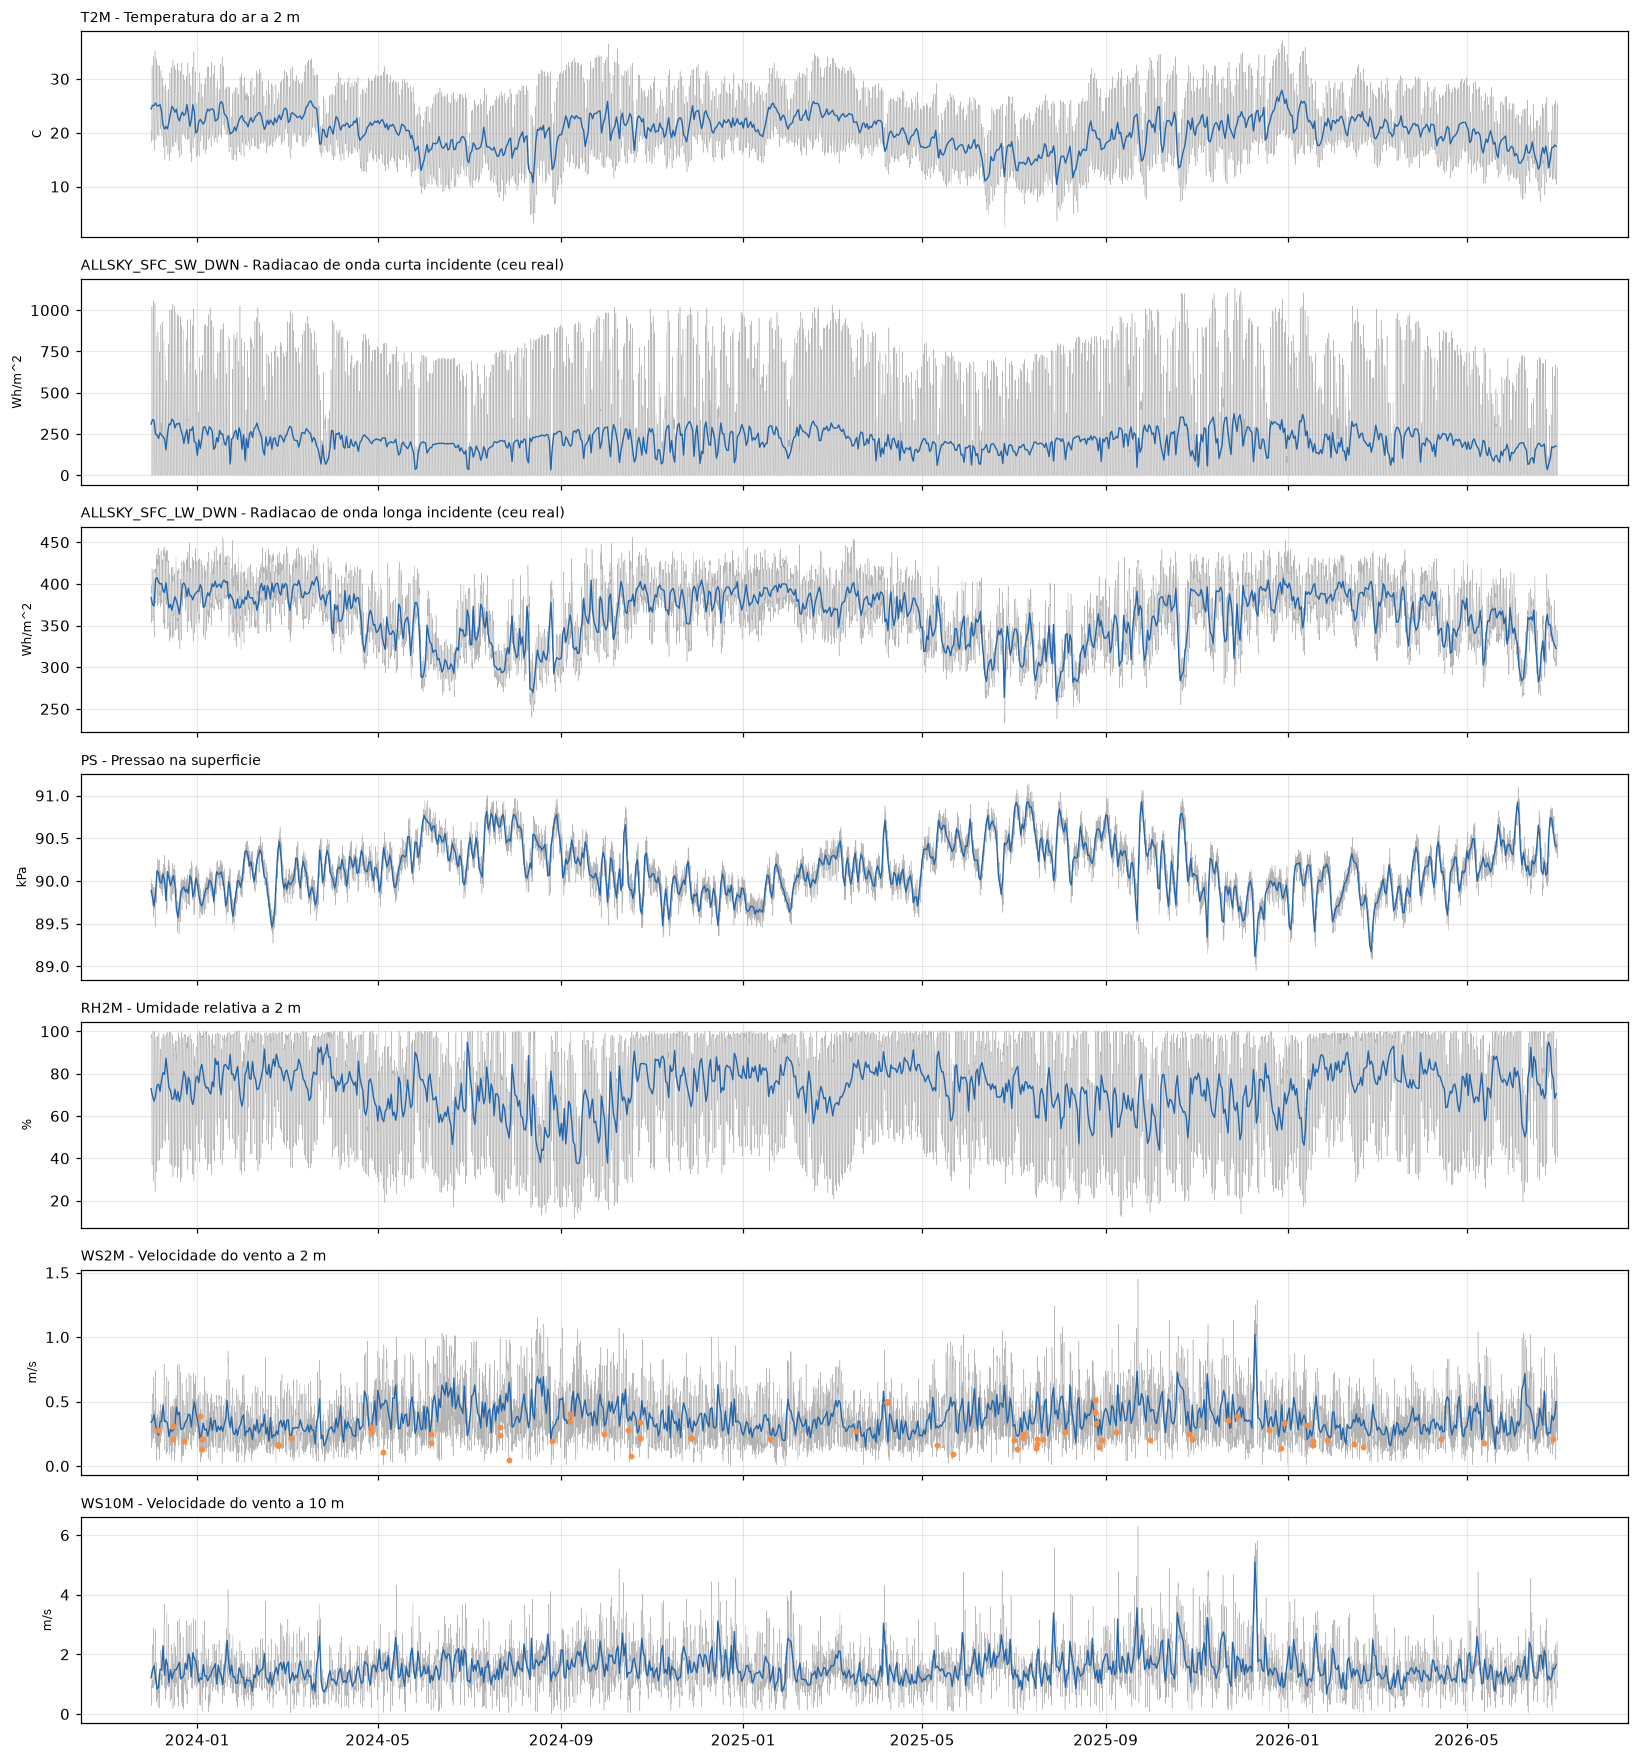

In [15]:
fig, eixos = plt.subplots(len(VARIAVEIS), 1, figsize=(15, 2.3 * len(VARIAVEIS)), sharex=True)
for eixo, variavel in zip(eixos, VARIAVEIS):
    serie = medidas[variavel]
    eixo.plot(serie, color="0.7", lw=0.3)
    eixo.plot(serie.resample("D").mean(), color="#2166ac", lw=0.9)
    marcado = estranho[variavel] & (regra_do_valor[variavel] != "umidade_100")
    eixo.scatter(serie.index[marcado], serie[marcado], color="#fd8d3c", s=8, zorder=3)
    eixo.set_ylabel(UNIDADES[variavel], fontsize=8)
    eixo.set_title(f"{variavel} - {parametros.set_index('variavel').loc[variavel, 'descricao']}", loc="left", fontsize=9)
fig.tight_layout()
plt.show()

### 6.2 Médias mensais

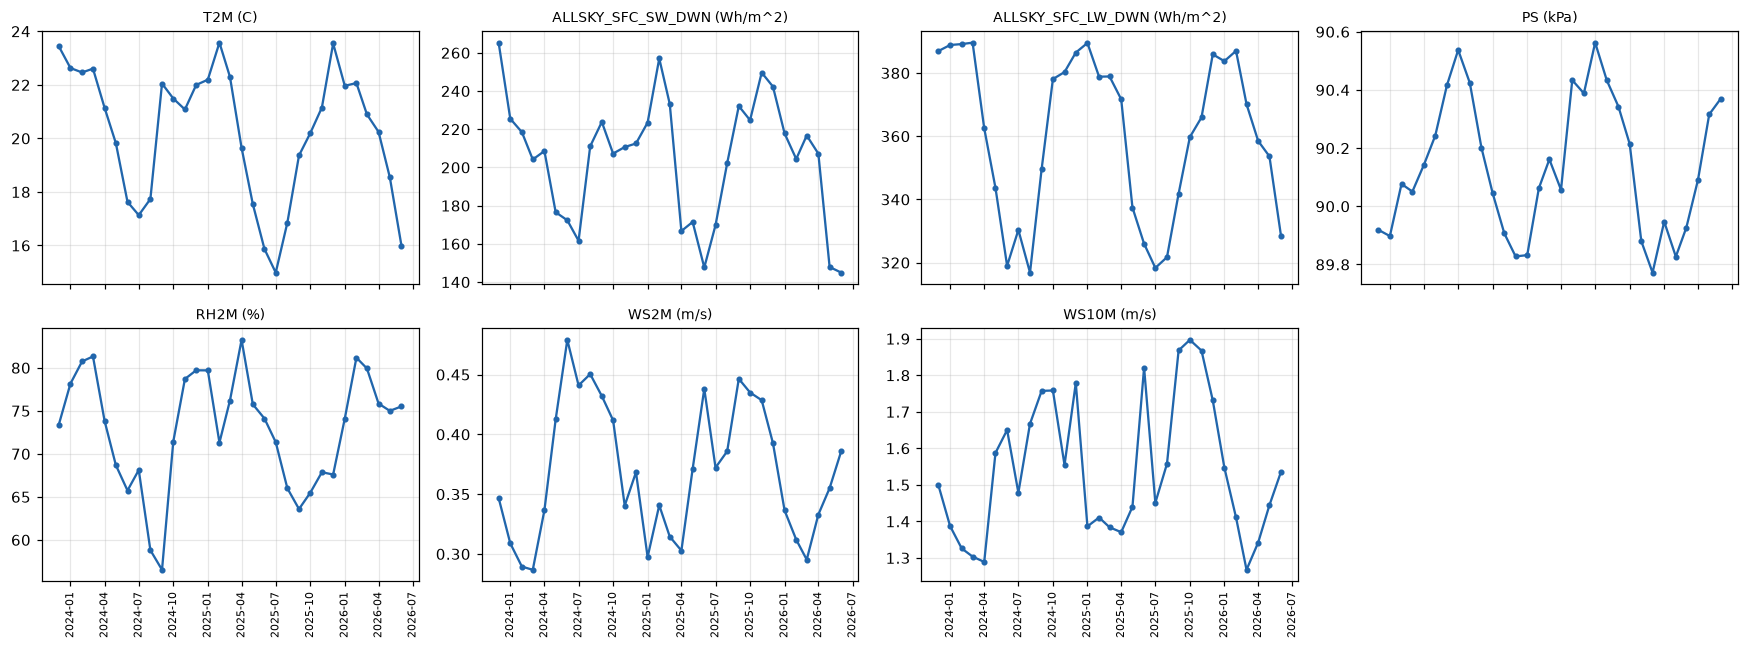

,T2M,ALLSKY_SFC_SW_DWN,ALLSKY_SFC_LW_DWN,PS,RH2M,WS2M,WS10M
tempo,,,,,,,
2023-12-01,23.44,265.31,386.96,89.92,73.40,0.35,1.50
2024-01-01,22.63,225.50,388.87,89.90,78.17,0.31,1.39
2024-02-01,22.46,218.47,389.16,90.08,80.74,0.29,1.33
2024-03-01,22.61,204.15,389.61,90.05,81.32,0.29,1.30
2024-04-01,21.14,208.58,362.52,90.14,73.82,0.34,1.29
2024-05-01,19.82,176.54,343.64,90.24,68.69,0.41,1.59
2024-06-01,17.63,172.34,318.99,90.42,65.74,0.48,1.65
2024-07-01,17.13,161.61,330.34,90.54,68.12,0.44,1.48
2024-08-01,17.74,211.07,316.84,90.42,58.81,0.45,1.67


In [16]:
media_mensal = medidas.resample("MS").mean()
fig, eixos = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
for eixo, variavel in zip(eixos.flat, VARIAVEIS):
    eixo.plot(media_mensal.index, media_mensal[variavel], "o-", ms=3, color="#2166ac")
    eixo.set_title(f"{variavel} ({UNIDADES[variavel]})", fontsize=9)
    eixo.tick_params(axis="x", rotation=90, labelsize=7)
eixos.flat[-1].axis("off")
fig.tight_layout()
plt.show()
display(media_mensal.round(2))

### 6.3 Ciclo diurno médio por estação do ano

Média de cada hora do dia em **hora local**, separada por estação (verão = dez–fev, outono = mar–mai,
inverno = jun–ago, primavera = set–nov). Cada ponto fica no **meio** da hora que ele representa (ex.:
o valor de 14:00–14:59 local fica em 14:30).

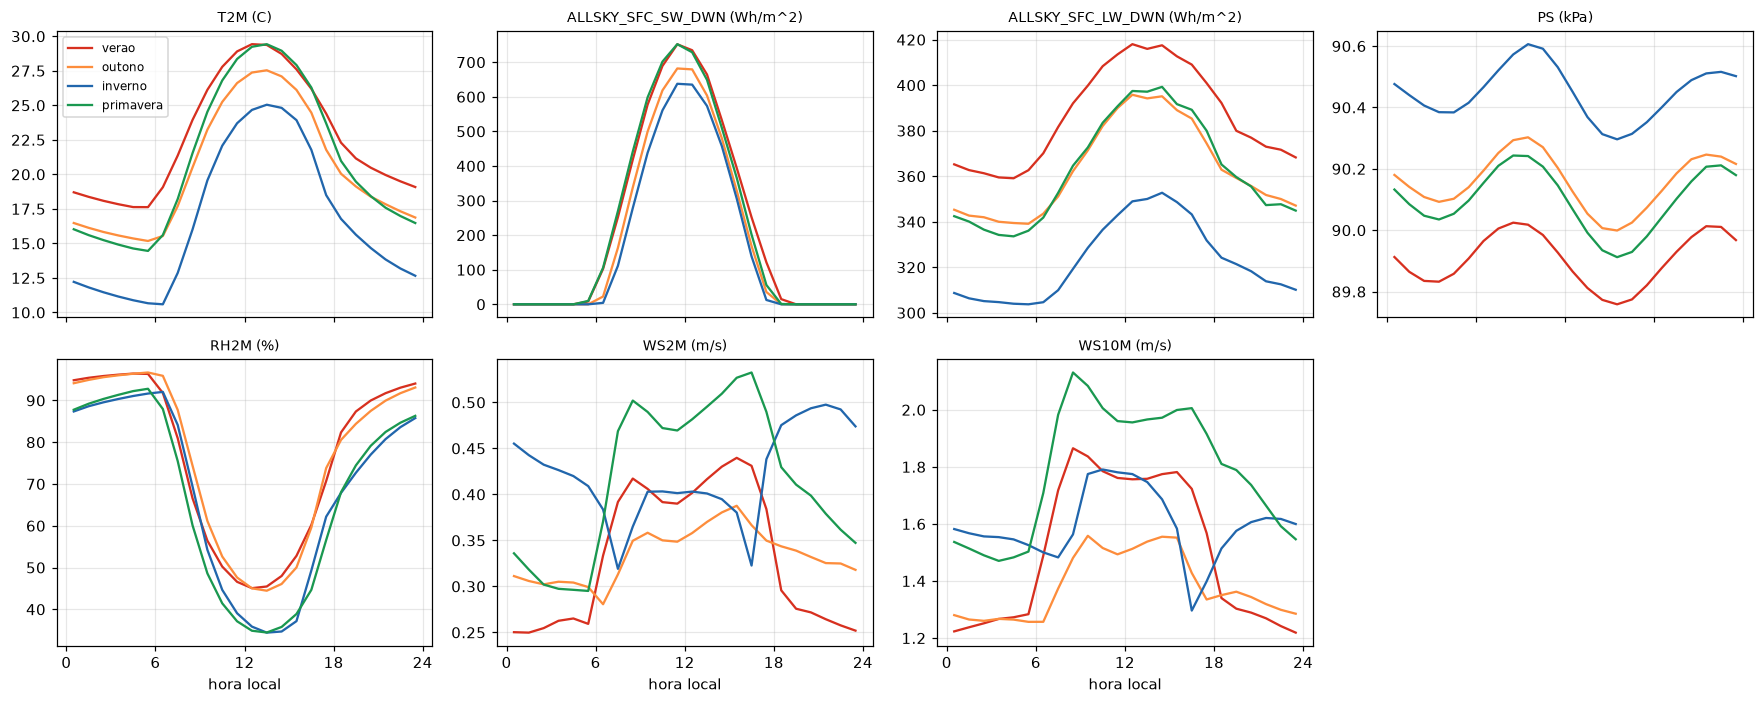

In [17]:
ESTACOES = {12: "verao", 1: "verao", 2: "verao", 3: "outono", 4: "outono", 5: "outono",
            6: "inverno", 7: "inverno", 8: "inverno", 9: "primavera", 10: "primavera", 11: "primavera"}
CORES_ESTACAO = {"verao": "#d7301f", "outono": "#fd8d3c", "inverno": "#2166ac", "primavera": "#1a9850"}

hora_local = (medidas.index + FUSO_LOCAL).hour
estacao = medidas.index.month.map(ESTACOES)
fig, eixos = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
for eixo, variavel in zip(eixos.flat, VARIAVEIS):
    ciclo = medidas[variavel].groupby([estacao, hora_local]).mean().unstack(0)
    for nome, cor in CORES_ESTACAO.items():
        eixo.plot(ciclo.index + 0.5, ciclo[nome], color=cor, label=nome)
    eixo.set_title(f"{variavel} ({UNIDADES[variavel]})", fontsize=9)
    eixo.set_xticks(range(0, 25, 6))
eixos.flat[0].legend(fontsize=8)
for eixo in eixos[1]:
    eixo.set_xlabel("hora local")
eixos.flat[-1].axis("off")
fig.tight_layout()
plt.show()

### 6.4 Mapas dia × hora

Cada coluna é um dia; cada linha, uma hora do dia (**hora local**); a cor é o valor. Mostra de uma vez
o ciclo diurno, as estações e episódios como frentes frias ou dias nublados.

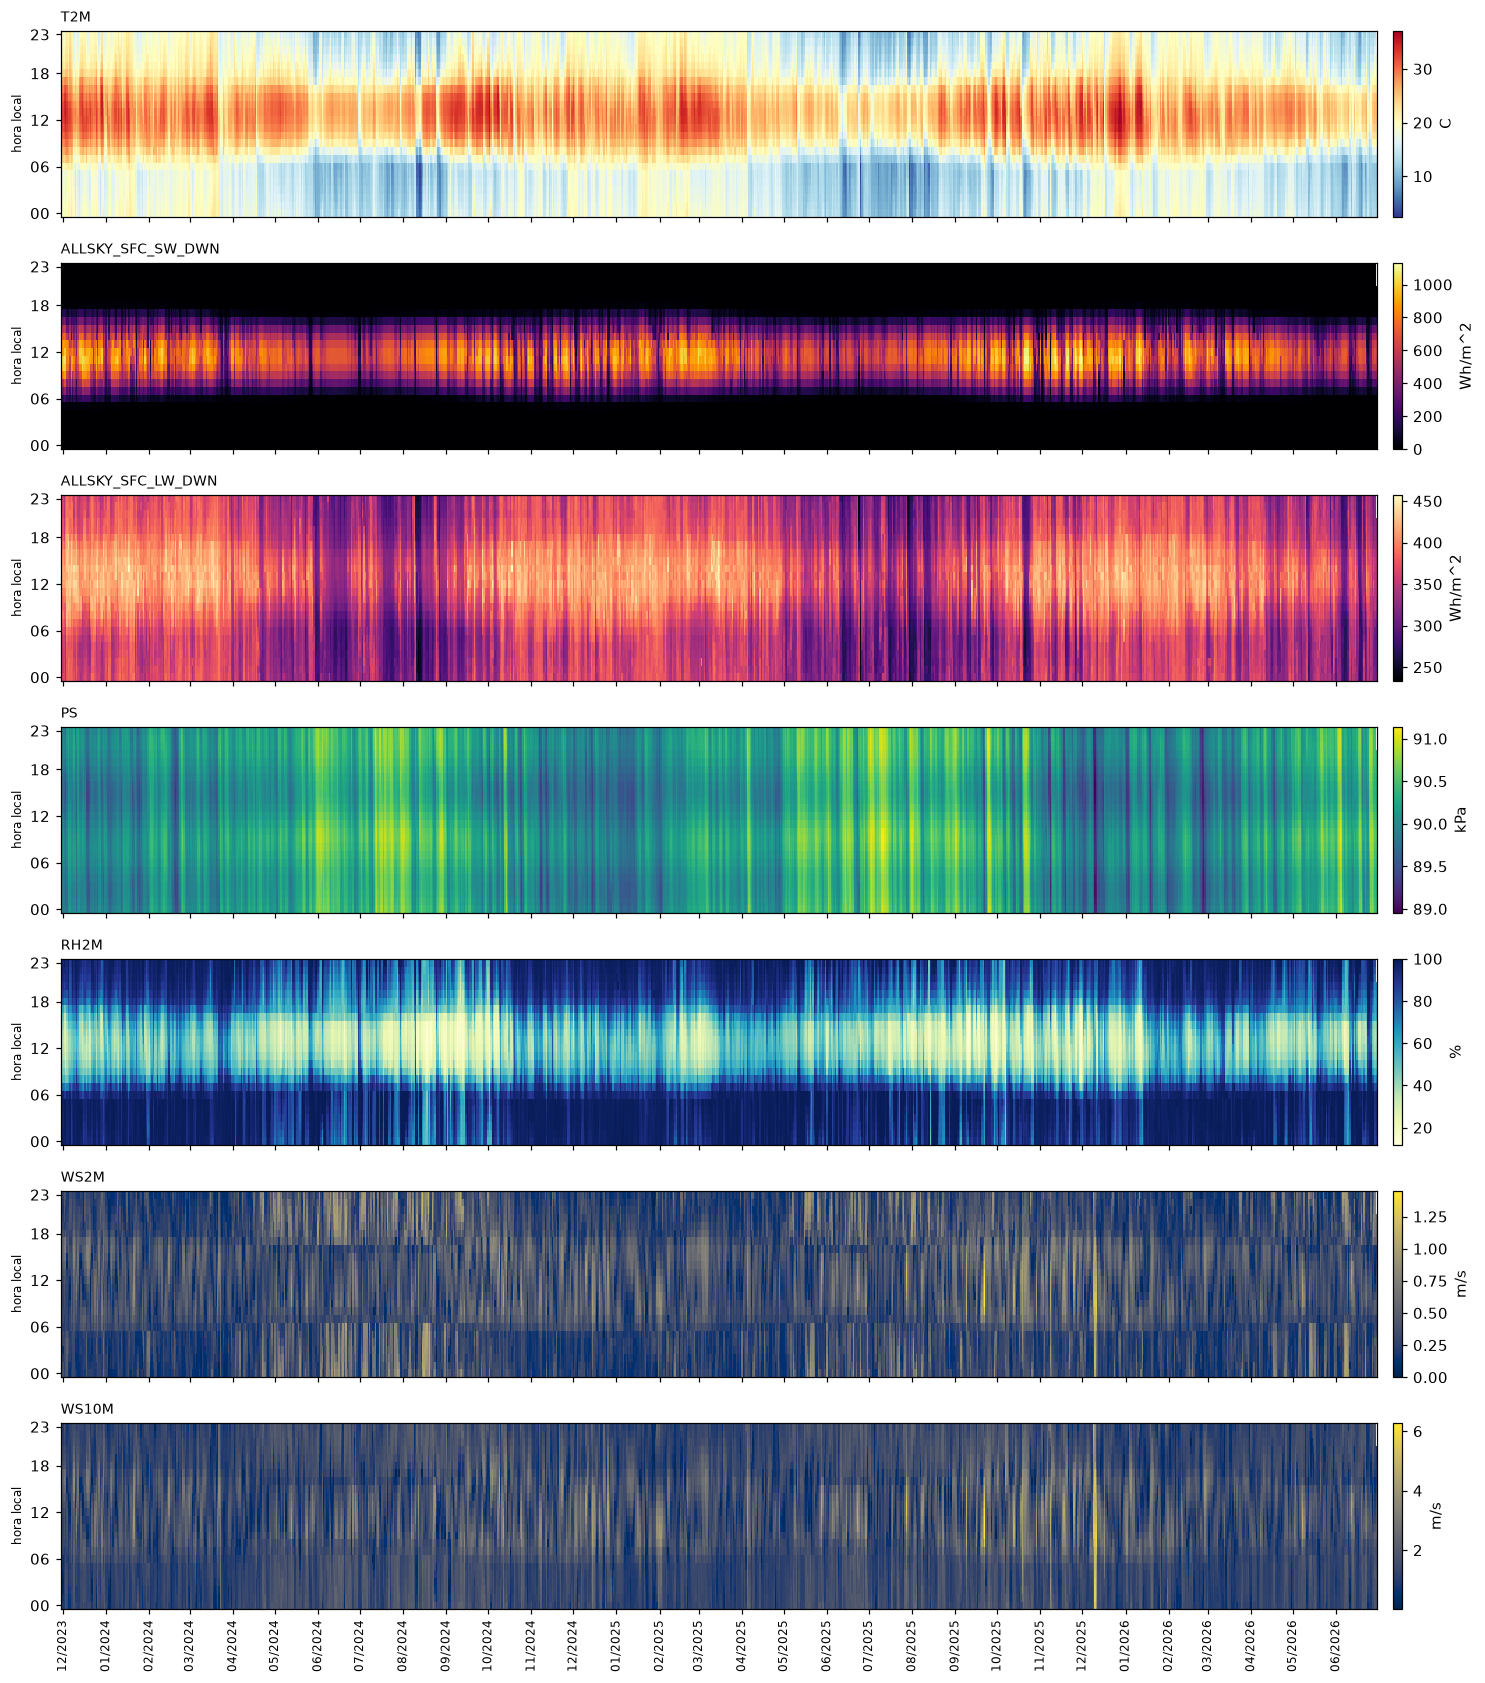

In [18]:
local = medidas.index + FUSO_LOCAL
dias_mapa = pd.date_range(local.normalize().min(), local.normalize().max(), freq="D")
coluna = (local.normalize() - dias_mapa[0]).days.to_numpy()
linha = local.hour.to_numpy()
CMAPS = {"T2M": "RdYlBu_r", SW: "inferno", LW: "magma", "PS": "viridis", "RH2M": "YlGnBu",
         "WS2M": "cividis", "WS10M": "cividis"}

fig, eixos = plt.subplots(len(VARIAVEIS), 1, figsize=(15, 2.2 * len(VARIAVEIS)), sharex=True)
for eixo, variavel in zip(eixos, VARIAVEIS):
    imagem = np.full((24, len(dias_mapa)), np.nan)
    imagem[linha, coluna] = medidas[variavel].to_numpy()
    figura = eixo.imshow(imagem, aspect="auto", interpolation="nearest", origin="lower", cmap=CMAPS.get(variavel))
    fig.colorbar(figura, ax=eixo, pad=0.01, label=UNIDADES[variavel])
    eixo.set_yticks([0, 6, 12, 18, 23], ["00", "06", "12", "18", "23"])
    eixo.set_ylabel("hora local", fontsize=8)
    eixo.set_title(variavel, loc="left", fontsize=9)
    eixo.grid(False)
meses = [i for i, dia in enumerate(dias_mapa) if dia.day == 1]
eixos[-1].set_xticks(meses, [dias_mapa[i].strftime("%m/%Y") for i in meses], rotation=90, fontsize=8)
fig.tight_layout()
plt.show()

### 6.5 Distribuições

Histogramas dos valores horários. Na onda curta, as horas da noite (zero) ficam de fora para não
esconder o resto.

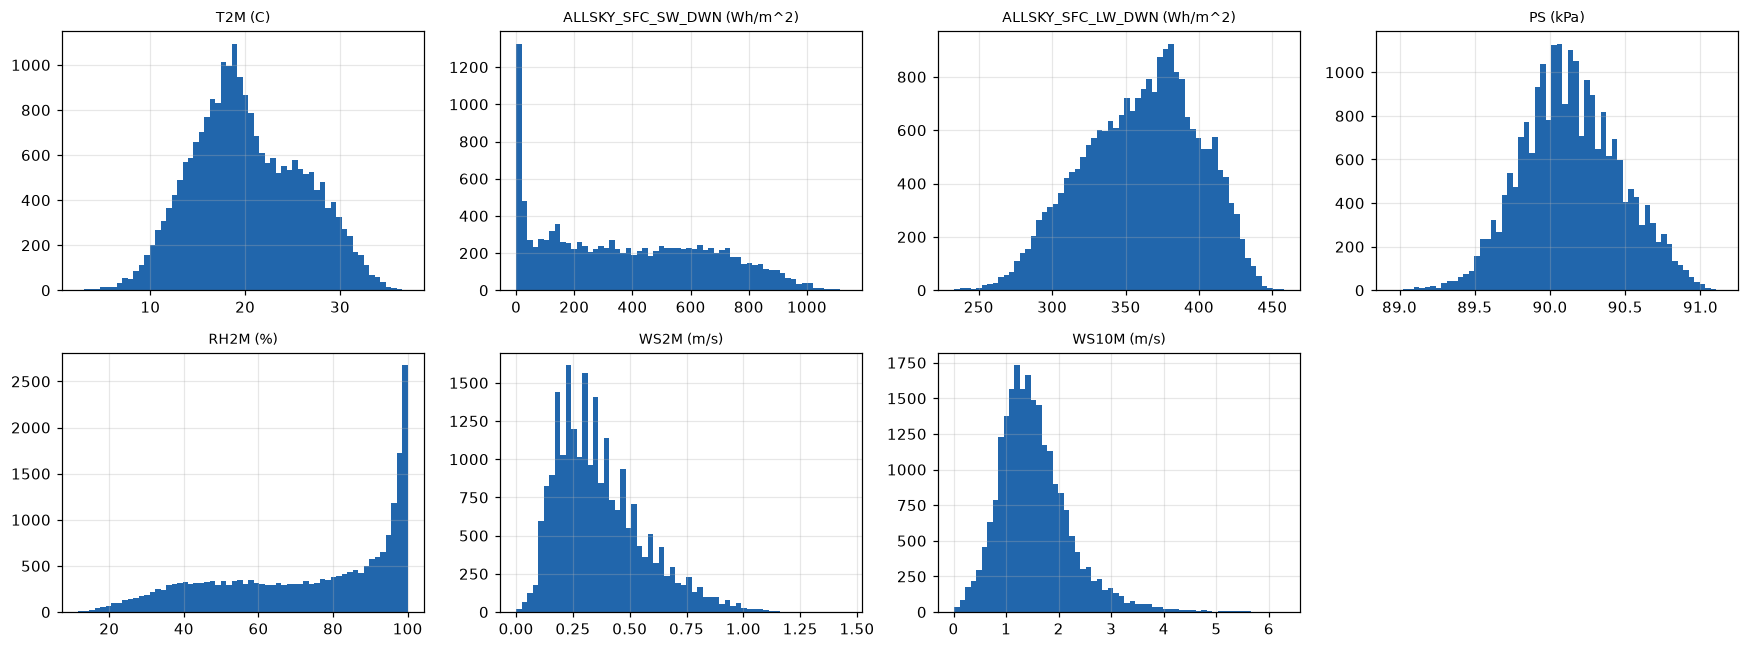

In [19]:
fig, eixos = plt.subplots(2, 4, figsize=(16, 6))
for eixo, variavel in zip(eixos.flat, VARIAVEIS):
    serie = medidas[variavel]
    if variavel == SW:
        serie = serie[toa > 0]
    eixo.hist(serie.dropna(), bins=60, color="#2166ac")
    eixo.set_title(f"{variavel} ({UNIDADES[variavel]})", fontsize=9)
eixos.flat[-1].axis("off")
fig.tight_layout()
plt.show()

## 7. Resumo consolidado

Uma linha por variável: faixa de valores, quanto falta e quantos valores caíram em cada regra.

In [20]:
regras_por_variavel = [
    ", ".join(f"{nome} ({(regra_do_valor[v] == nome).sum()})" for nome in regras if (regra_do_valor[v] == nome).any())
    for v in VARIAVEIS
]
resumo = pd.DataFrame({
    "fonte": [FONTES[v] for v in VARIAVEIS],
    "unidade": [UNIDADES[v] for v in VARIAVEIS],
    "minimo": medidas.min().values,
    "media": medidas.mean().values,
    "maximo": medidas.max().values,
    "faltando": faltante.sum().values,
    "estranhos": estranho.sum().values,
    "estranhos_%": (100 * estranho.mean()).values,
    "regras": regras_por_variavel,
}, index=pd.Index(VARIAVEIS, name="variavel")).round(2)
display(resumo)

certa = teste_horario.sort_values(["horas_com_sol_a_noite", "horas_acima_do_topo"]).iloc[0]["convencao"]
horas = f"{len(grade):,}".replace(",", ".")
print(f"Periodo: {grade[0]:%d/%m/%Y %H:%M} a {grade[-1]:%d/%m/%Y %H:%M} UTC, {horas} horas")
print(f"Registros ausentes: {registro_ausente.sum()} | horas repetidas: {repetidos.sum()} | "
      f"valores -999: {int(faltante.sum().sum())}")
print(f"Convencao de horario que bate com o sol: {certa}")
print(f"Pressao levada a {ALTITUDE_ESTACAO} m: {pressao_na_estacao.mean():.1f} hPa"
      + (f" (SONDA: {pressao_sonda:.1f} hPa)" if COMPARAR_PRESSAO_SONDA else ""))
print(f"Vento: WS10M/WS2M mediana {razao_mediana:.2f} -> z0 equivalente {z0:.2f} m")

,fonte,unidade,minimo,media,maximo,faltando,estranhos,estranhos_%,regras
variavel,,,,,,,,,
T2M,MERRA-2,C,2.39,20.25,37.14,0,0,0.00,
ALLSKY_SFC_SW_DWN,CERES,Wh/m^2,0.00,204.97,1132.95,0,0,0.00,
ALLSKY_SFC_LW_DWN,CERES,Wh/m^2,233.20,360.51,457.60,0,0,0.00,
PS,MERRA-2,kPa,88.95,90.14,91.14,0,0,0.00,
RH2M,MERRA-2,%,11.66,72.85,100.00,0,1001,4.42,umidade_100 (1001)
WS2M,MERRA-2,m/s,0.00,0.37,1.45,0,78,0.34,"vento_2m_maior_10m (60), constante (18)"
WS10M,MERRA-2,m/s,0.01,1.54,6.28,0,0,0.00,


Periodo: 01/12/2023 00:00 a 30/06/2026 23:00 UTC, 22.632 horas
Registros ausentes: 0 | horas repetidas: 0 | valores -999: 0
Convencao de horario que bate com o sol: HR = inicio da hora
Pressao levada a 574 m: 950.4 hPa (SONDA: 951.4 hPa)
Vento: WS10M/WS2M mediana 4.48 -> z0 equivalente 1.26 m


### Leitura do resumo

*Escrita a partir do arquivo `POWER_Point_Hourly_20231201_20260630_022d69S_045d01W_UTC.csv` (rodada de
05/11/2026). Se o arquivo mudar, confira os números das tabelas acima.*

**Resultado (o que os dados mostram)**

- **Completo:** 22.632 horas (01/12/2023 a 30/06/2026), sem hora ausente, sem hora repetida e sem
  nenhum −999 nas 7 variáveis.
- **Nenhum valor impossível, fora da faixa plausível ou com salto brusco.** Não há sol à noite nem
  radiação acima do topo da atmosfera.
- **Umidade = 100 % em 1001 horas (4,4 %)**, em 231 episódios de até 11 h, **todos à noite** (93 % entre 0 h e 7 h local).
- **Vento a 2 m:** 60 horas com `WS2M` maior que `WS10M` (diferença mediana de 0,08 m/s e máxima de 0,23 m/s, sempre com `WS2M` ≤ 0,51 m/s)
  e 18 horas em 3 trechos com o mesmo valor por 6 h seguidas (0,16 a 0,50 m/s).

**Evidência computacional (contas que confirmam algo)**

- **`HR` = início da hora.** Nessa hipótese há 0 horas com sol à noite e 0 acima do topo; na hipótese
  "fim da hora" seriam 707 e 1438. Para comparar com a SONDA (que marca o **fim**), o valor de `HR = 14`
  do NASA POWER corresponde ao registro das **15:00** da SONDA.
- **A pressão é coerente com a altitude.** ~901 hPa na elevação do modelo (1028 m) e **950,4 hPa** quando
  levada a 574 m, contra **951,4 hPa** medidos na SONDA no mesmo período (diferença de 1 hPa).

**Interpretação física (o que provavelmente explica)**

- A umidade em 100 % é ar saturado (nevoeiro e orvalho noturnos no Vale do Paraíba), não falha. O
  modelo limita a umidade em 100 %.
- O vento do NASA POWER é **fraco** (média de 0,37 m/s a 2 m e 1,5 m/s a 10 m), e a razão 10 m / 2 m (4,5)
  equivale a uma rugosidade de ~1,3 m, típica de floresta ou relevo acidentado. A célula de ~55 × 65 km
  inclui a Serra da Mantiqueira e não representa o terreno aberto da estação. Os casos de `WS2M > WS10M`
  e de valor constante são efeitos do modelo com vento quase nulo.
- Os ciclos diurnos são coerentes: temperatura máxima por volta das 13 h local, umidade inversa a ela,
  radiação centrada no meio-dia solar e a **maré semidiurna** na pressão (dois máximos por dia, ~10 h e
  ~22 h). As mudanças rápidas do vento no nascer e no pôr do sol mudam de horário com a estação, como
  esperado da camada-limite.

**Cuidados para usar estes dados**

1. Não é medida no ponto, é a média de uma célula de grade: espere diferenças em relação à SONDA,
   principalmente no **vento** e na **pressão absoluta**. Para pressão, use a variação (anomalia) ou
   corrija a altitude.
2. Ao comparar ou juntar com a SONDA, **desloque 1 h** (início → fim da hora).
3. Não há falhas a preencher: as séries podem ir direto para o tratamento (`series_prontas/`) sem
   interpolação.

## 8. Exportação

Com `SALVAR_TABELAS = True`, as tabelas vão para `02_dados/nasa_power/diagnostico/`:

- `resumo_variaveis.csv`: a tabela da seção 7;
- `resumo_faltantes.csv` e `intervalos_faltantes.csv`: quanto falta e cada falha;
- `valores_estranhos_contagem.csv` e `valores_estranhos_episodios.csv`: o resultado das regras da seção 4;
- `teste_convencao_horario.csv`: a tabela da seção 5.1.

In [21]:
if SALVAR_TABELAS:
    PASTA_SAIDA.mkdir(parents=True, exist_ok=True)
    resumo.to_csv(PASTA_SAIDA / "resumo_variaveis.csv")
    resumo_faltantes.to_csv(PASTA_SAIDA / "resumo_faltantes.csv", index=False)
    falhas.to_csv(PASTA_SAIDA / "intervalos_faltantes.csv", index=False)
    contagem.to_csv(PASTA_SAIDA / "valores_estranhos_contagem.csv")
    episodios_estranhos.to_csv(PASTA_SAIDA / "valores_estranhos_episodios.csv", index=False)
    teste_horario.to_csv(PASTA_SAIDA / "teste_convencao_horario.csv", index=False)
    for arquivo in sorted(PASTA_SAIDA.iterdir()):
        print(arquivo.name)

intervalos_faltantes.csv
resumo_faltantes.csv
resumo_variaveis.csv
teste_convencao_horario.csv
valores_estranhos_contagem.csv
valores_estranhos_episodios.csv
